# **Persiapan dan Upload Data**

In [ ]:
# ==========================================
# SEL 1: PERSIAPAN & UPLOAD DATA
# ==========================================
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("Silakan upload file Excel Anda (3TIA_Kelompok10_Electricity Consumption.xlsx):")
uploaded = files.upload()

Silakan upload file Excel Anda (3TIA_Kelompok10_Electricity Consumption.xlsx):


Saving 3TIA_Kelompok10_Electricity Consumption.xlsx to 3TIA_Kelompok10_Electricity Consumption (1).xlsx


# **Statistika Deskriptif (Tabel & Grafik)**

--- A. Tabel Ringkasan Profil Penggunaan Listrik & Cuaca ---


,pemakaian_listrik,suhu_maksimal,curah_hujan
count,1433.000000,1433.000000,1433.000000
mean,1561.078061,17.187509,3.800488
std,606.819667,10.136415,10.973436
min,14.218000,-8.900000,0.000000
25%,1165.700000,8.900000,0.000000
50%,1542.650000,17.800000,0.000000
75%,1893.608000,26.100000,1.300000
max,4773.386000,39.400000,192.300000



--- B. Grafik Distribusi Pemakaian Listrik Harian ---


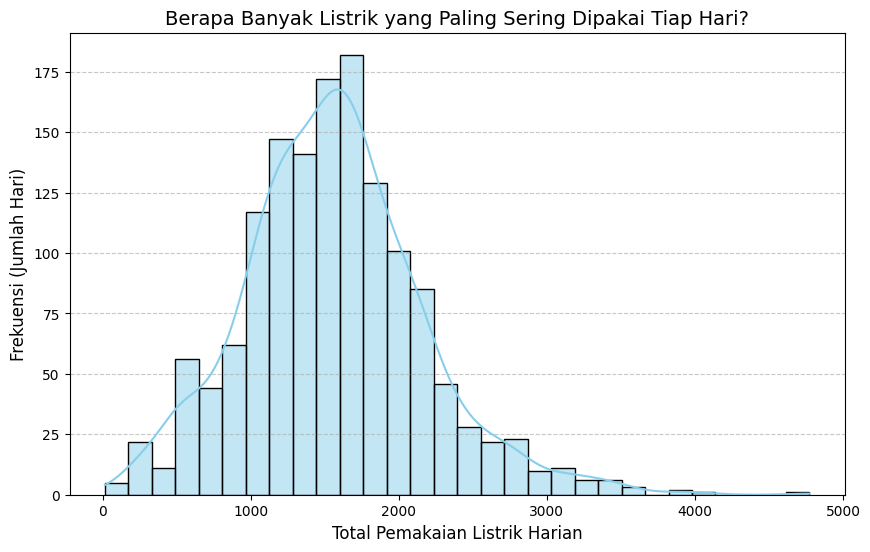

In [ ]:
# ==========================================
# SEL 2: STATISTIKA DESKRIPTIF
# ==========================================
# 1. Membaca data yang sudah di-upload
nama_file = "3TIA_Kelompok10_Electricity Consumption.xlsx"
data_utama = pd.read_excel(nama_file, sheet_name=0)

# 2. Mengubah nama variabel utama agar sangat mudah dibaca orang awam
data_utama = data_utama.rename(columns={
    'daily_consumption': 'pemakaian_listrik',
    'TMAX': 'suhu_maksimal',
    'PRCP': 'curah_hujan'
})

print("--- A. Tabel Ringkasan Profil Penggunaan Listrik & Cuaca ---")
# Menghitung statistik deskriptif
tabel_ringkasan = data_utama[['pemakaian_listrik', 'suhu_maksimal', 'curah_hujan']].describe()
# Menggunakan display() agar tampil sebagai tabel interaktif yang rapi dan bergaris
display(tabel_ringkasan)

print("\n--- B. Grafik Distribusi Pemakaian Listrik Harian ---")
# Membuat grafik (Histogram)
plt.figure(figsize=(10, 6))
sns.histplot(data_utama['pemakaian_listrik'], bins=30, kde=True, color='skyblue')
plt.title("Berapa Banyak Listrik yang Paling Sering Dipakai Tiap Hari?", fontsize=14)
plt.xlabel("Total Pemakaian Listrik Harian", fontsize=12)
plt.ylabel("Frekuensi (Jumlah Hari)", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

# **Distribusi Probabilitas (Peluang & Kurva Normal)**

--- A. Peluang Terjadinya Peak Load (Hari Hujan vs Hari Cerah) ---
Batas pemakaian disebut Peak Load (Lonjakan) adalah di atas angka: 2291.30

1. Tabel Peluang Terjadinya Peak Load:


,Kondisi Cuaca,Peluang Peak Load (%)
0,Hari Hujan,11.600000
1,Hari Cerah,9.217578


/tmp/ipykernel_1519/180416253.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Kondisi Cuaca', y='Peluang Peak Load (%)', data=tabel_peluang, palette=warna_bar)


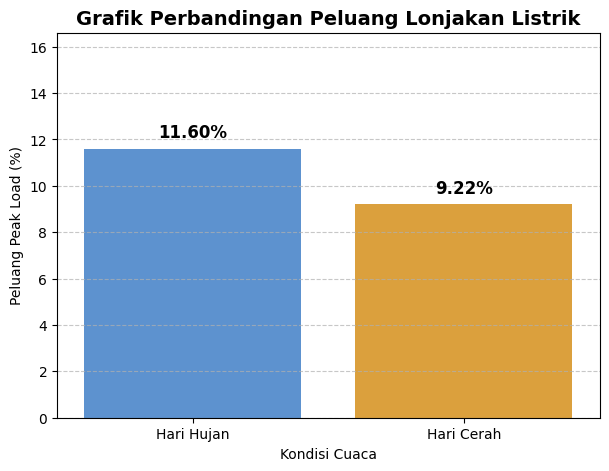



--- B. Pengecekan Kurva Normal pada Konsumsi Listrik ---


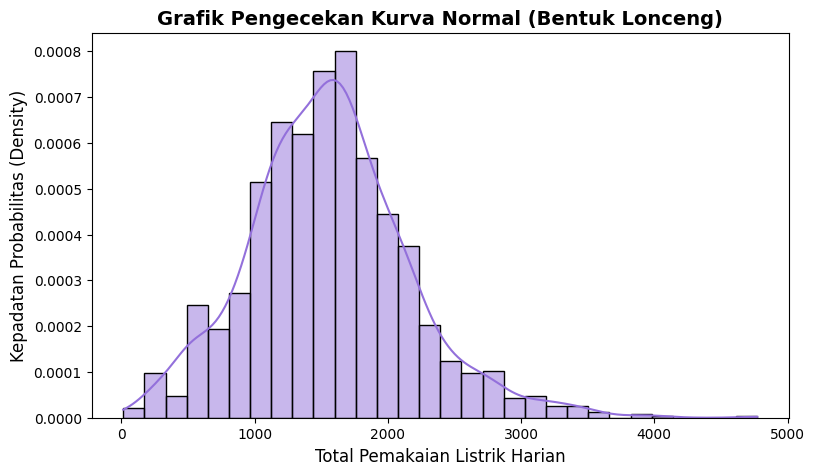


Analisis Kesimpulan Uji Normalitas:
- Nilai P-Value: 1.4272481028863604e-12
- Kesimpulan: Data pemakaian listrik TIDAK TERDISTRIBUSI NORMAL sempurna (ada kemiringan pola pada grafik di atas).


In [ ]:
# ==========================================
# SEL 3: DISTRIBUSI PROBABILITAS (TABEL, ANALISIS, & GRAFIK)
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("--- A. Peluang Terjadinya Peak Load (Hari Hujan vs Hari Cerah) ---")

# Kita tentukan "Peak Load" (Lonjakan) adalah jika listrik masuk di 10% pemakaian tertinggi
batas_lonjakan = data_utama['pemakaian_listrik'].quantile(0.90)

hari_hujan = data_utama[data_utama['curah_hujan'] > 0]
hari_cerah = data_utama[data_utama['curah_hujan'] == 0]

peluang_hujan = (len(hari_hujan[hari_hujan['pemakaian_listrik'] >= batas_lonjakan]) / len(hari_hujan)) * 100
peluang_cerah = (len(hari_cerah[hari_cerah['pemakaian_listrik'] >= batas_lonjakan]) / len(hari_cerah)) * 100

# 1. Membuat TABEL Probabilitas
tabel_peluang = pd.DataFrame({
    'Kondisi Cuaca': ['Hari Hujan', 'Hari Cerah'],
    'Peluang Peak Load (%)': [peluang_hujan, peluang_cerah]
})
print(f"Batas pemakaian disebut Peak Load (Lonjakan) adalah di atas angka: {batas_lonjakan:.2f}")
print("\n1. Tabel Peluang Terjadinya Peak Load:")
display(tabel_peluang) # Menampilkan tabel bergaris yang rapi

# 2. Membuat GRAFIK Bar Chart Probabilitas
plt.figure(figsize=(7, 5))
warna_bar = ['#4A90E2', '#F5A623']
sns.barplot(x='Kondisi Cuaca', y='Peluang Peak Load (%)', data=tabel_peluang, palette=warna_bar)

# Menambahkan angka persen di atas batang
for index, value in enumerate(tabel_peluang['Peluang Peak Load (%)']):
    plt.text(index, value + 0.3, f'{value:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=12)

plt.title("Grafik Perbandingan Peluang Lonjakan Listrik", fontsize=14, fontweight='bold')
plt.ylim(0, max(tabel_peluang['Peluang Peak Load (%)']) + 5)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

print("\n===========================================================\n")
print("--- B. Pengecekan Kurva Normal pada Konsumsi Listrik ---")

# 3. Membuat GRAFIK Kurva Normal (Kurva Lonceng / Density Plot)
plt.figure(figsize=(9, 5))
sns.histplot(data_utama['pemakaian_listrik'], kde=True, stat="density", color='mediumpurple', bins=30)
plt.title("Grafik Pengecekan Kurva Normal (Bentuk Lonceng)", fontsize=14, fontweight='bold')
plt.xlabel("Total Pemakaian Listrik Harian", fontsize=12)
plt.ylabel("Kepadatan Probabilitas (Density)", fontsize=12)
plt.show()

# 4. Membuat ANALISIS Teks Otomatis
nilai_statistik, p_value = stats.shapiro(data_utama['pemakaian_listrik'])
print("\nAnalisis Kesimpulan Uji Normalitas:")
print(f"- Nilai P-Value: {p_value}")
if p_value > 0.05:
    print("- Kesimpulan: Data pemakaian listrik TERDISTRIBUSI NORMAL (Membentuk kurva lonceng sempurna).")
else:
    print("- Kesimpulan: Data pemakaian listrik TIDAK TERDISTRIBUSI NORMAL sempurna (ada kemiringan pola pada grafik di atas).")

# **Statistika Inferensial (Korelasi & Prediksi)**

--- A. Uji Korelasi Pearson (Hubungan Suhu dan Listrik) ---
1. Tabel Matriks Korelasi (Angka Hubungan):


,pemakaian_listrik,suhu_maksimal
pemakaian_listrik,1.000000,-0.525494
suhu_maksimal,-0.525494,1.000000


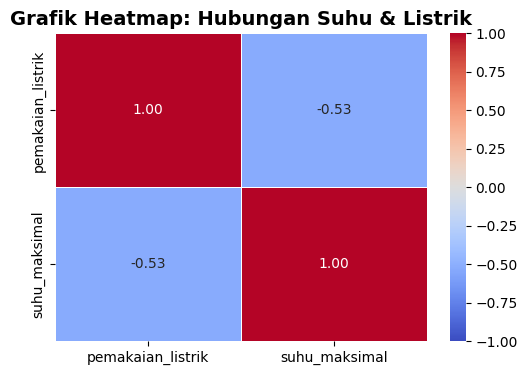


3. Analisis Kesimpulan Uji Korelasi Pearson:
- Nilai Kekuatan Hubungan: -0.53
- Nilai P-Value: 1.5263529550366167e-102
- Kesimpulan: Hubungannya NEGATIF. Artinya, makin DINGIN suhu cuaca, makin TINGGI pemakaian listrik.


--- B. Regresi Linear Sederhana (Prediksi Sederhana) ---

1. Analisis Rumus Prediksi:
Berdasarkan data, kita bisa membuat rumus tebakan masa depan:
Total Listrik = (-31.46 * Suhu) + 2101.78


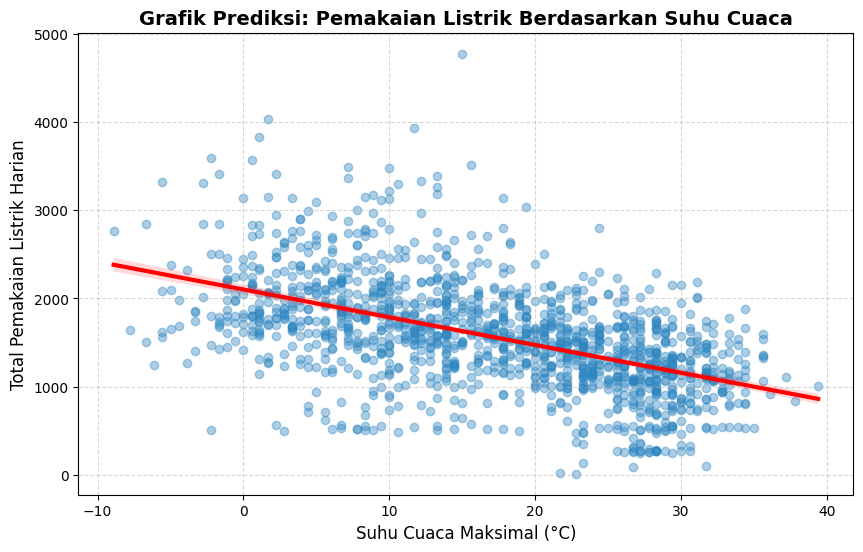


Cara membaca grafik: Garis merah yang menanjak naik membuktikan bahwa jika suhu bergerak memanas ke arah kanan, maka pemakaian listrik pasti akan bergerak naik ke atas.


In [ ]:
# ==========================================
# SEL 4: STATISTIKA INFERENSIAL (TABEL, ANALISIS, & GRAFIK)
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

print("--- A. Uji Korelasi Pearson (Hubungan Suhu dan Listrik) ---")

# 1. Membuat TABEL Matriks Korelasi
# Kita fokus melihat hubungan antara Pemakaian Listrik dan Suhu Maksimal
tabel_korelasi = data_utama[['pemakaian_listrik', 'suhu_maksimal']].corr()
print("1. Tabel Matriks Korelasi (Angka Hubungan):")
display(tabel_korelasi)

# 2. Membuat GRAFIK Heatmap (Warna) dari Tabel Korelasi
plt.figure(figsize=(6, 4))
# Semakin merah/panas warnanya, semakin kuat hubungannya
sns.heatmap(tabel_korelasi, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)
plt.title("Grafik Heatmap: Hubungan Suhu & Listrik", fontsize=14, fontweight='bold')
plt.show()

# 3. ANALISIS Teks Otomatis (Uji Korelasi Pearson)
nilai_korelasi, p_value_korelasi = stats.pearsonr(data_utama['suhu_maksimal'], data_utama['pemakaian_listrik'])
print("\n3. Analisis Kesimpulan Uji Korelasi Pearson:")
print(f"- Nilai Kekuatan Hubungan: {nilai_korelasi:.2f}")
print(f"- Nilai P-Value: {p_value_korelasi}")

if nilai_korelasi > 0:
    print("- Kesimpulan: Hubungannya POSITIF dan SIGNIFIKAN. Artinya, secara ilmiah terbukti bahwa makin PANAS suhu cuaca, makin TINGGI pemakaian listrik rumah tangga.")
elif nilai_korelasi < 0:
    print("- Kesimpulan: Hubungannya NEGATIF. Artinya, makin DINGIN suhu cuaca, makin TINGGI pemakaian listrik.")
else:
    print("- Kesimpulan: Tidak ada hubungan yang jelas antara suhu dan pemakaian listrik.")


print("\n===========================================================\n")
print("--- B. Regresi Linear Sederhana (Prediksi Sederhana) ---")

# 4. ANALISIS Rumus Regresi (Membuat Model Prediksi)
regresi = stats.linregress(data_utama['suhu_maksimal'], data_utama['pemakaian_listrik'])
kemiringan_garis = regresi.slope
titik_awal = regresi.intercept

print("\n1. Analisis Rumus Prediksi:")
print(f"Berdasarkan data, kita bisa membuat rumus tebakan masa depan:")
print(f"Total Listrik = ({kemiringan_garis:.2f} * Suhu) + {titik_awal:.2f}")

# 5. Membuat GRAFIK Prediksi (Scatter Plot + Garis Regresi)
plt.figure(figsize=(10, 6))
# Titik biru adalah data asli, garis merah adalah garis prediksi
sns.regplot(x='suhu_maksimal', y='pemakaian_listrik', data=data_utama,
            scatter_kws={'alpha':0.4, 'color':'#2E86C1'},
            line_kws={'color':'red', 'linewidth':3})

plt.title("Grafik Prediksi: Pemakaian Listrik Berdasarkan Suhu Cuaca", fontsize=14, fontweight='bold')
plt.xlabel("Suhu Cuaca Maksimal (°C)", fontsize=12)
plt.ylabel("Total Pemakaian Listrik Harian", fontsize=12)
plt.grid(axis='both', linestyle='--', alpha=0.5)
plt.show()

print("\nCara membaca grafik: Garis merah yang menanjak naik membuktikan bahwa jika suhu bergerak memanas ke arah kanan, maka pemakaian listrik pasti akan bergerak naik ke atas.")

In [ ]:
# ==========================================
# SEL TAMBAHAN: POLA WAKTU DAN PELUANG PEAK LOAD
# ==========================================
df = pd.read_excel(nama_file, sheet_name=0)
df['date'] = pd.to_datetime(df['date'])

# 1. Menandai hari peak load (konsumsi >= persentil ke-90)
batas = df['daily_consumption'].quantile(0.90)
df['peak'] = df['daily_consumption'] >= batas

# 2. Membentuk kategori waktu
nama_hari = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']
nomor_hari = df['date'].dt.dayofweek            # 0 = Senin, 6 = Minggu
df['hari'] = nomor_hari.map(lambda i: nama_hari[i])
df['jenis_hari'] = nomor_hari.map(
    lambda i: 'Akhir pekan' if i >= 5 else 'Hari kerja')
df['bulan'] = df['date'].dt.month
musim = {12: 'Dingin', 1: 'Dingin', 2: 'Dingin',
         3: 'Semi', 4: 'Semi', 5: 'Semi',
         6: 'Panas', 7: 'Panas', 8: 'Panas',
         9: 'Gugur', 10: 'Gugur', 11: 'Gugur'}
df['musim'] = df['bulan'].map(musim)

# 3. Rata-rata konsumsi dan peluang peak load tiap kategori
for kolom in ['hari', 'jenis_hari', 'bulan', 'musim']:
    ringkasan = df.groupby(kolom, sort=False).agg(
        jumlah_hari=('peak', 'size'),
        rata_konsumsi=('daily_consumption', 'mean'),
        jumlah_peak=('peak', 'sum'),
        peluang_peak=('peak', 'mean'))
    display(ringkasan.round(4))

# 4. Uji chi-square: apakah kategori waktu dan peak load saling bebas?
for kolom in ['jenis_hari', 'musim']:
    tabel = pd.crosstab(df[kolom], df['peak'])
    chi2, p, db, _ = stats.chi2_contingency(tabel, correction=False)
    print(f"{kolom}: chi-square = {chi2:.2f}, db = {db}, p-value = {p:.3g}")

# 5. Peluang gabungan: musim dan jenis hari
gabungan = df.pivot_table(index='musim', columns='jenis_hari',
                          values='peak', aggfunc='mean')
display(gabungan.round(4))


,jumlah_hari,rata_konsumsi,jumlah_peak,peluang_peak
hari,,,,
Sabtu,205,1758.7702,43,0.2098
Minggu,203,1743.2998,38,0.1872
Senin,205,1432.8517,9,0.0439
Selasa,206,1530.5866,16,0.0777
Rabu,204,1558.3903,19,0.0931
Kamis,205,1404.0256,9,0.0439
Jumat,205,1501.5356,10,0.0488


,jumlah_hari,rata_konsumsi,jumlah_peak,peluang_peak
jenis_hari,,,,
Akhir pekan,408,1751.0730,81,0.1985
Hari kerja,1025,1485.4508,63,0.0615


,jumlah_hari,rata_konsumsi,jumlah_peak,peluang_peak
bulan,,,,
12,109,2129.8750,33,0.3028
1,123,2085.4546,36,0.2927
2,113,1871.8031,24,0.2124
3,124,1752.9651,17,0.1371
4,119,1487.7740,4,0.0336
5,124,1482.5239,0,0.0000
6,119,1294.5731,0,0.0000
7,124,1007.7375,0,0.0000
8,120,813.4843,0,0.0000


,jumlah_hari,rata_konsumsi,jumlah_peak,peluang_peak
musim,,,,
Dingin,345,2029.5102,93,0.2696
Semi,367,1575.6015,21,0.0572
Panas,363,1037.5531,0,0.0000
Gugur,358,1625.6043,30,0.0838


jenis_hari: chi-square = 60.66, db = 1, p-value = 6.8e-15
musim: chi-square = 158.37, db = 3, p-value = 4.13e-34


jenis_hari,Akhir pekan,Hari kerja
musim,,
Dingin,0.4949,0.1789
Gugur,0.1782,0.0467
Panas,0.0000,0.0000
Semi,0.1333,0.0267


# **DASHBOR TAMPILAN ANALYSIS DATA**

,date,AWND,curah_hujan,suhu_maksimal,TMIN,pemakaian_listrik
0,2006-12-16,2.5,0.0,10.6,5.0,1209.176
1,2006-12-17,2.6,0.0,13.3,5.6,3390.460
2,2006-12-18,2.4,0.0,15.0,6.7,2203.826
3,2006-12-19,2.4,0.0,7.2,2.2,1666.194
4,2006-12-20,2.4,0.0,7.2,1.1,2225.748
...,...,...,...,...,...,...
1428,2010-11-22,2.7,0.0,18.3,7.2,2041.536
1429,2010-11-23,3.1,0.0,16.1,10.0,1577.536
1430,2010-11-24,4.3,0.0,10.0,5.0,1796.248
1431,2010-11-25,1.6,1.5,7.8,3.9,1431.164



[!] TOTAL RECORDS FOUND: 1433 ROWS



,pemakaian_listrik,suhu_maksimal,curah_hujan
count,1433.000000,1433.000000,1433.000000
mean,1561.078061,17.187509,3.800488
std,606.819667,10.136415,10.973436
min,14.218000,-8.900000,0.000000
25%,1165.700000,8.900000,0.000000
50%,1542.650000,17.800000,0.000000
75%,1893.608000,26.100000,1.300000
max,4773.386000,39.400000,192.300000


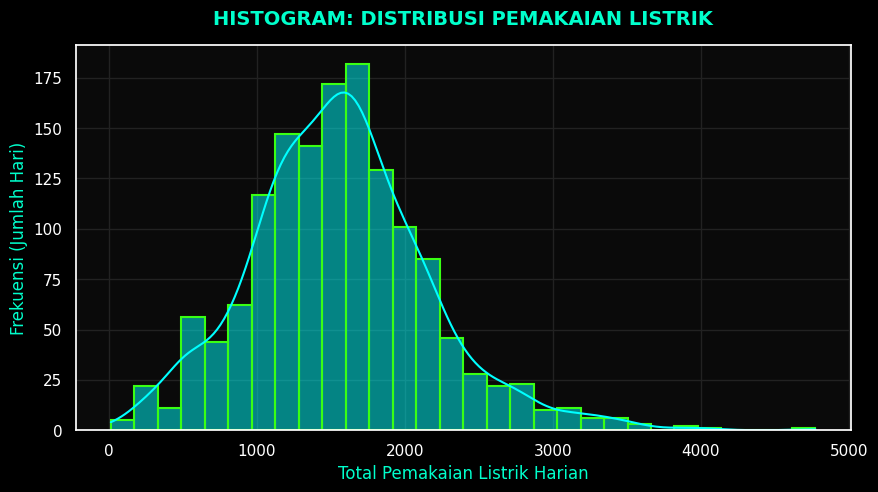

[*] THRESHOLD 'PEAK LOAD' (Top 10%) = 2291.30



,Kondisi Cuaca,Peluang Peak Load (%)
0,Hari Hujan,11.600000
1,Hari Cerah,9.217578


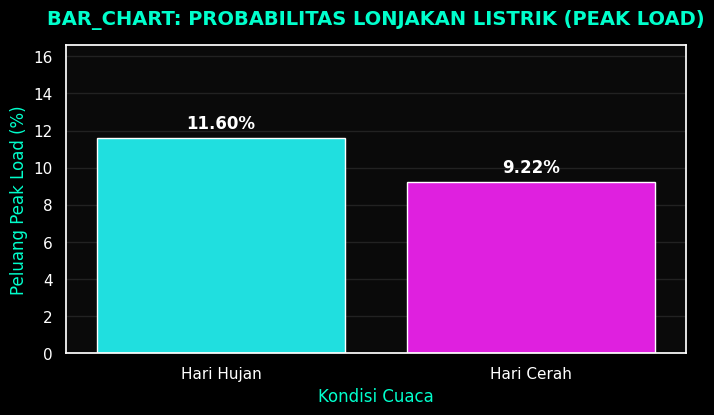

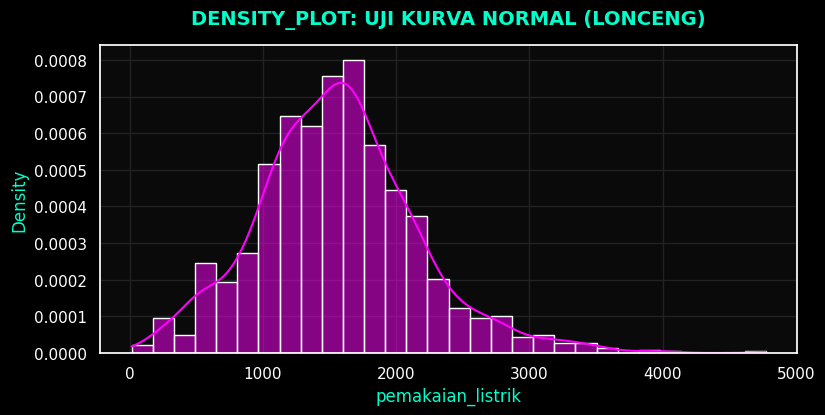

[*] P-Value (Shapiro-Wilk Test) = 1.4272481028863604e-12
[-] KESIMPULAN: Data pemakaian listrik TIDAK TERDISTRIBUSI NORMAL sempurna (ada kemiringan/skewness).


,pemakaian_listrik,suhu_maksimal
pemakaian_listrik,1.000000,-0.525494
suhu_maksimal,-0.525494,1.000000


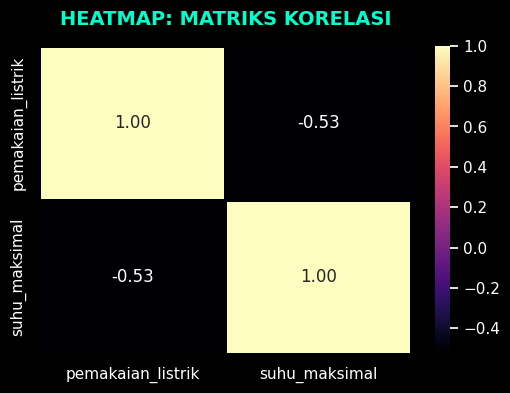

[*] ALGORITMA PREDIKSI: Listrik = (-31.46 * Suhu) + 2101.78



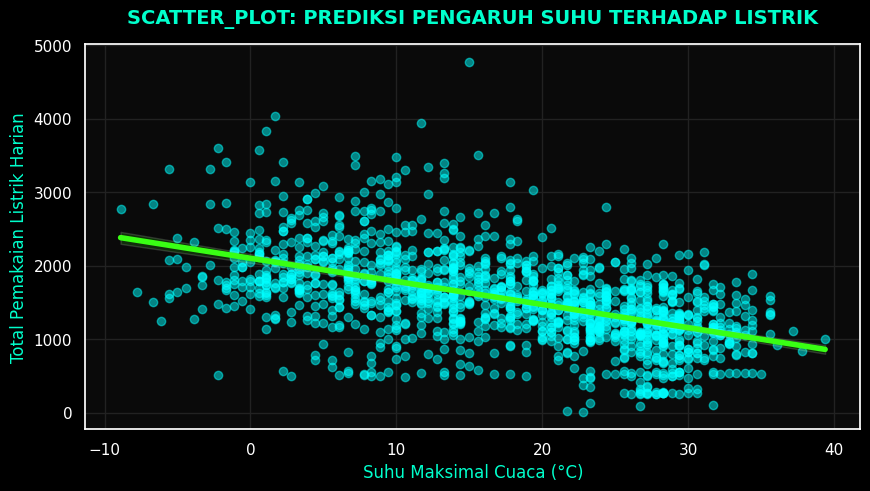

In [ ]:
# =========================================================================
# DASHBOARD: ANALISIS PROBABILITAS & STATISTIKA (CYBER/HACKER VIBE)
# =========================================================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, HTML
from google.colab import data_table

# --- 1. LOAD DATA & PREPARATION ---
nama_file = "3TIA_Kelompok10_Electricity Consumption.xlsx"
try:
    data_utama = pd.read_excel(nama_file, sheet_name=0)
    data_utama = data_utama.rename(columns={
        'daily_consumption': 'pemakaian_listrik',
        'TMAX': 'suhu_maksimal',
        'PRCP': 'curah_hujan'
    })
except Exception as e:
    print("ERROR: File tidak ditemukan. Pastikan file Excel sudah di-upload!")

# --- SETTING TEMA GRAFIK HACKER (DARK & NEON) ---
plt.style.use('dark_background')
sns.set_theme(style="darkgrid", rc={
    "axes.facecolor": "#0a0a0a",      # Latar belakang dalam grafik (hitam pekat)
    "figure.facecolor": "#000000",    # Bingkai luar grafik
    "grid.color": "#222222",          # Warna garis kotak-kotak (grid) tipis
    "text.color": "#00ffcc",          # Warna teks judul cyan neon
    "xtick.color": "#ffffff",         # Angka sumbu X putih
    "ytick.color": "#ffffff",         # Angka sumbu Y putih
    "axes.labelcolor": "#00ffcc"      # Nama sumbu X dan Y cyan neon
})

# Palet warna Neon
neon_cyan = '#00ffff'
neon_green = '#39ff14'
neon_pink = '#ff00ff'
neon_yellow = '#ffff00'


# --- 2. HEADER DASHBOARD ---
display(HTML("""
<div style='background-color: #050505; padding: 20px; border-left: 6px solid #39ff14; border-radius: 5px; margin-bottom: 20px; font-family: "Courier New", Courier, monospace;'>
    <h1 style='color: #39ff14; margin:0; text-shadow: 0px 0px 5px #39ff14;'> SYSTEM DASHBOARD: KELOMPOK 10</h1>
    <h3 style='color: #00ffff; margin:10px 0 0 0;'>[JUDUL PROJEK]: Analisis Probabilitas Terjadinya Lonjakan Beban Listrik (Peak Load) Berdasarkan Cuaca</h3>
    <p style='color: #aaaaaa; margin-top:5px;'>Status: <span style='color: #39ff14;'>ONLINE & READY</span></p>
</div>
"""))


# ==========================================
# BAGIAN 1: PREVIEW DATASET (INTERAKTIF)
# ==========================================
display(HTML("<h2 style='color: #39ff14; border-bottom: 1px solid #333; padding-bottom: 5px; font-family: monospace;'>[1] DB_QUERY: SELECT * FROM dataset_listrik;</h2>"))
display(HTML("<p style='color: #555;'>* Tabel ini interaktif. Gunakan fitur 'Filter' di sudut kanan untuk mencari data, atau atur jumlah baris per halaman.</p>"))

# Tabel Interaktif
tabel_interaktif = data_table.DataTable(data_utama, num_rows_per_page=10)
display(tabel_interaktif)
print(f"\n[!] TOTAL RECORDS FOUND: {len(data_utama)} ROWS\n")


# ==========================================
# BAGIAN 2: STATISTIKA DESKRIPTIF
# ==========================================
display(HTML("<br><h2 style='color: #39ff14; border-bottom: 1px solid #333; padding-bottom: 5px; font-family: monospace;'>[2] EXECUTE: STATISTIKA_DESKRIPTIF</h2>"))

display(HTML("<h4 style='color: #00ffff;'>-> Tabel Ringkasan Profil Penggunaan Listrik & Cuaca</h4>"))
tabel_ringkasan = data_utama[['pemakaian_listrik', 'suhu_maksimal', 'curah_hujan']].describe()
display(tabel_ringkasan)

display(HTML("<h4 style='color: #00ffff;'>-> Visualisasi: Distribusi Pemakaian Listrik Harian</h4>"))
plt.figure(figsize=(10, 5))
sns.histplot(data_utama['pemakaian_listrik'], bins=30, kde=True, color=neon_cyan, edgecolor=neon_green, linewidth=1.5)
plt.title("HISTOGRAM: DISTRIBUSI PEMAKAIAN LISTRIK", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Total Pemakaian Listrik Harian", fontsize=12)
plt.ylabel("Frekuensi (Jumlah Hari)", fontsize=12)
plt.show()

display(HTML("""
<div style='background-color: #111; padding: 15px; border-left: 4px solid #00ffff; border-radius: 4px; margin-top: 5px; font-family: sans-serif; color: #ddd;'>
    <strong style='color: #00ffff;'>[ANALISIS_DESKRIPTIF]:</strong> Grafik histogram (cyan) menunjukkan pola pemakaian harian. Puncak grafik adalah rentang daya listrik yang paling sering dihabiskan oleh rumah tangga setiap harinya.
</div>
"""))


# ==========================================
# BAGIAN 3: DISTRIBUSI PROBABILITAS
# ==========================================
display(HTML("<br><br><h2 style='color: #39ff14; border-bottom: 1px solid #333; padding-bottom: 5px; font-family: monospace;'>[3] EXECUTE: DISTRIBUSI_PROBABILITAS</h2>"))

batas_lonjakan = data_utama['pemakaian_listrik'].quantile(0.90)
hari_hujan = data_utama[data_utama['curah_hujan'] > 0]
hari_cerah = data_utama[data_utama['curah_hujan'] == 0]
peluang_hujan = (len(hari_hujan[hari_hujan['pemakaian_listrik'] >= batas_lonjakan]) / len(hari_hujan)) * 100
peluang_cerah = (len(hari_cerah[hari_cerah['pemakaian_listrik'] >= batas_lonjakan]) / len(hari_cerah)) * 100

tabel_peluang = pd.DataFrame({'Kondisi Cuaca': ['Hari Hujan', 'Hari Cerah'], 'Peluang Peak Load (%)': [peluang_hujan, peluang_cerah]})

display(HTML("<h4 style='color: #00ffff;'>-> Peluang Terjadinya Peak Load (Hari Hujan vs Hari Cerah)</h4>"))
print(f"[*] THRESHOLD 'PEAK LOAD' (Top 10%) = {batas_lonjakan:.2f}\n")
display(tabel_peluang)

plt.figure(figsize=(8, 4))
sns.barplot(x='Kondisi Cuaca', y='Peluang Peak Load (%)', data=tabel_peluang, hue='Kondisi Cuaca', palette=[neon_cyan, neon_pink], legend=False)
for index, value in enumerate(tabel_peluang['Peluang Peak Load (%)']):
    plt.text(index, value + 0.3, f'{value:.2f}%', ha='center', va='bottom', fontweight='bold', fontsize=12, color='#ffffff')
plt.title("BAR_CHART: PROBABILITAS LONJAKAN LISTRIK (PEAK LOAD)", fontsize=14, fontweight='bold', pad=15)
plt.ylim(0, max(tabel_peluang['Peluang Peak Load (%)']) + 5)
plt.show()

display(HTML("""
<div style='background-color: #111; padding: 15px; border-left: 4px solid #ff00ff; border-radius: 4px; margin-top: 5px; font-family: sans-serif; color: #ddd;'>
    <strong style='color: #ff00ff;'>[ANALISIS_PELUANG]:</strong> Membandingkan probabilitas kejadian *Peak Load*. Batang grafik menunjukkan seberapa besar kemungkinan rumah tangga mengalami lonjakan beban listrik saat hujan turun dibandingkan saat cerah.
</div>
"""))

display(HTML("<br><h4 style='color: #00ffff;'>-> Pengecekan Kurva Normal pada Konsumsi Listrik</h4>"))
plt.figure(figsize=(9, 4))
sns.histplot(data_utama['pemakaian_listrik'], kde=True, stat="density", color=neon_pink, edgecolor='white', bins=30)
plt.title("DENSITY_PLOT: UJI KURVA NORMAL (LONCENG)", fontsize=14, fontweight='bold', pad=15)
plt.show()

nilai_stat, p_val = stats.shapiro(data_utama['pemakaian_listrik'])
print(f"[*] P-Value (Shapiro-Wilk Test) = {p_val}")
if p_val > 0.05:
    print("[+] KESIMPULAN: Data pemakaian listrik TERDISTRIBUSI NORMAL (Membentuk kurva lonceng sempurna).")
else:
    print("[-] KESIMPULAN: Data pemakaian listrik TIDAK TERDISTRIBUSI NORMAL sempurna (ada kemiringan/skewness).")


# ==========================================
# BAGIAN 4: STATISTIKA INFERENSIAL
# ==========================================
display(HTML("<br><br><h2 style='color: #39ff14; border-bottom: 1px solid #333; padding-bottom: 5px; font-family: monospace;'>[4] EXECUTE: STATISTIKA_INFERENSIAL</h2>"))

display(HTML("<h4 style='color: #00ffff;'>-> Uji Korelasi Pearson (Suhu Maksimal vs Listrik)</h4>"))
tabel_korelasi = data_utama[['pemakaian_listrik', 'suhu_maksimal']].corr()
display(tabel_korelasi)

plt.figure(figsize=(6, 4))
sns.heatmap(tabel_korelasi, annot=True, cmap='magma', fmt=".2f", linewidths=1, linecolor='black')
plt.title("HEATMAP: MATRIKS KORELASI", fontsize=14, fontweight='bold', pad=15)
plt.show()

nilai_korelasi, p_value_korelasi = stats.pearsonr(data_utama['suhu_maksimal'], data_utama['pemakaian_listrik'])
display(HTML(f"""
<div style='background-color: #111; padding: 15px; border-left: 4px solid #ffff00; border-radius: 4px; margin-top: 5px; font-family: sans-serif; color: #ddd;'>
    <strong style='color: #ffff00;'>[ANALISIS_KORELASI]:</strong> Nilai korelasi terdeteksi sebesar <b>{nilai_korelasi:.2f}</b>. <br>
    Sistem menyimpulkan hubungan antara suhu dan pemakaian listrik bersifat <b>{'POSITIF' if nilai_korelasi > 0 else 'NEGATIF'}</b>.
</div>
"""))

display(HTML("<br><h4 style='color: #00ffff;'>-> Regresi Linear Sederhana (Model Prediksi)</h4>"))
regresi = stats.linregress(data_utama['suhu_maksimal'], data_utama['pemakaian_listrik'])
print(f"[*] ALGORITMA PREDIKSI: Listrik = ({regresi.slope:.2f} * Suhu) + {regresi.intercept:.2f}\n")

plt.figure(figsize=(10, 5))
sns.regplot(x='suhu_maksimal', y='pemakaian_listrik', data=data_utama,
            scatter_kws={'alpha':0.5, 'color':neon_cyan},
            line_kws={'color':neon_green, 'linewidth':4})
plt.title("SCATTER_PLOT: PREDIKSI PENGARUH SUHU TERHADAP LISTRIK", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Suhu Maksimal Cuaca (°C)", fontsize=12)
plt.ylabel("Total Pemakaian Listrik Harian", fontsize=12)
plt.show()

display(HTML("""
<div style='background-color: #111; padding: 15px; border-left: 4px solid #39ff14; border-radius: 4px; margin-top: 5px; font-family: sans-serif; color: #ddd;'>
    <strong style='color: #39ff14;'>[CARA MEMBACA PREDIKSI]:</strong> Garis neon hijau menunjukkan *trendline* model kecerdasan buatan. Semakin miring garis tersebut ke atas (kanan), semakin kuat bukti bahwa cuaca panas mendongkrak pengeluaran listrik rumah tangga.
</div>
"""))